In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

Image shape: (459, 493, 3)


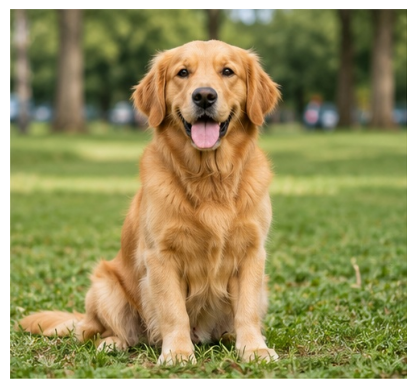

In [2]:
image = Image.open(
    "images/image1.jpg"
).convert("RGB")

image_np = np.array(image)

print("Image shape:", image_np.shape)

plt.imshow(image_np)
plt.axis("off")
plt.show()

## 实验 1：Canny threshold
固定同一张图片，只改变低、高阈值，比较保留的边缘结构。先运行上面的图片加载单元格。

(50, 100)：边缘像素 33476，占比 14.79%
(100, 200)：边缘像素 18628，占比 8.23%
(150, 250)：边缘像素 12768，占比 5.64%


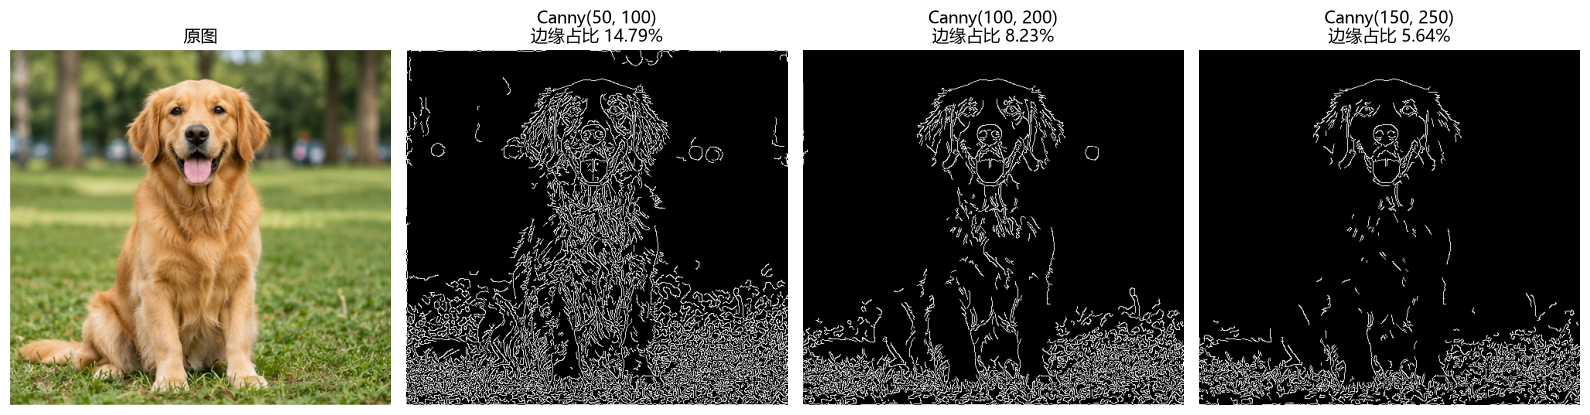

In [3]:
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
thresholds = [(50, 100), (100, 200), (150, 250)]
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
axes[0].imshow(image_np)
axes[0].set_title('原图')
for ax, (low, high) in zip(axes[1:], thresholds):
    edge = cv2.Canny(gray, low, high)
    ratio = np.count_nonzero(edge) / edge.size
    ax.imshow(edge, cmap='gray')
    ax.set_title(f'Canny({low}, {high})\n边缘占比 {ratio:.2%}')
    print(f'({low}, {high})：边缘像素 {np.count_nonzero(edge)}，占比 {ratio:.2%}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)

**回答：阈值升高后，Condition 中弱对比度的细节减少，结构变得更稀疏。**

观察狗的毛发和草地：低阈值保留更多纹理及杂乱边缘；高阈值主要保留较强的明暗边界，但也可能丢失狗的部分轮廓。高阈值并不保证得到完整的主体轮廓。

Canny 的高阈值确定强边缘，低阈值筛选可连接到强边缘的弱边缘。它依据梯度和连通性，不理解哪个物体是主体。

## 实验 2：Mask 对齐
先在原图上手工画狗的近似 Mask，再将原图宽高放大约 1.5 倍。

错误组沿用原 Mask 坐标，将其放在新画布左上角，以展示错位；正确组对 Mask 同步缩放。注意：不同尺寸的 Image 与 Mask 直接混合通常会报形状不匹配错误。

下面的顶点只适用于 `image1.jpg`，换图需要重新标注。

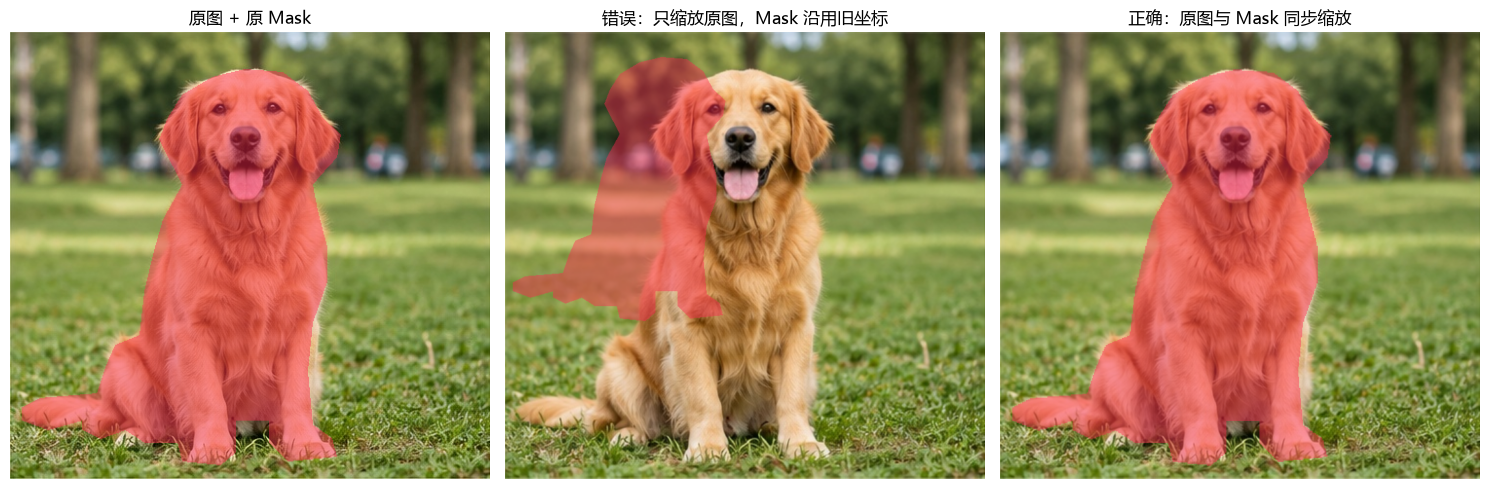

原图和原 Mask： (459, 493) (459, 493)
只缩放原图： (688, 740) (459, 493)
同步缩放： (688, 740) (688, 740)


In [4]:
h, w = image_np.shape[:2]
# 手工近似轮廓，并非精确分割真值；尾巴和毛发边界存在误差。
vertices = np.array([
    [.49,.083],[.57,.09],[.62,.13],[.65,.19],[.69,.23],
    [.68,.28],[.63,.34],[.64,.40],[.66,.48],[.66,.56],
    [.63,.65],[.62,.76],[.63,.88],[.67,.91],[.68,.95],
    [.58,.96],[.54,.92],[.54,.87],[.47,.87],[.47,.94],
    [.44,.97],[.36,.96],[.35,.92],[.28,.92],[.24,.89],
    [.19,.91],[.15,.89],[.15,.87],[.08,.89],[.025,.87],
    [.025,.84],[.06,.82],[.18,.81],[.20,.75],[.22,.70],
    [.27,.68],[.28,.58],[.30,.49],[.32,.42],[.36,.34],
    [.34,.30],[.31,.24],[.33,.19],[.36,.14],[.42,.10]
], dtype=np.float32)
points = np.rint(vertices * [w-1, h-1]).astype(np.int32)
mask = np.zeros((h, w), dtype=np.uint8)
cv2.fillPoly(mask, [points], 255)

def overlay(rgb, m):
    assert rgb.shape[:2] == m.shape, 'Image 与 Mask 尺寸不匹配'
    result = rgb.copy()
    selected = m > 0
    result[selected] = np.rint(0.55 * rgb[selected] + 0.45 * np.array([255, 40, 80])).astype(np.uint8)
    return result

new_w, new_h = round(w*1.5), round(h*1.5)
resized_image = cv2.resize(image_np, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
# 错误示范：旧 Mask 不做缩放，只按旧坐标放到新画布中。
wrong_mask = np.zeros((new_h, new_w), dtype=np.uint8)
wrong_mask[:h, :w] = mask
# 正确示范：类别 Mask 用最近邻插值，保留 0/255 标签。
aligned_mask = cv2.resize(mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, rgb, m, title in zip(axes,
        [image_np, resized_image, resized_image],
        [mask, wrong_mask, aligned_mask],
        ['原图 + 原 Mask', '错误：只缩放原图，Mask 沿用旧坐标', '正确：原图与 Mask 同步缩放']):
    ax.imshow(overlay(rgb, m))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)
print('原图和原 Mask：', image_np.shape[:2], mask.shape)
print('只缩放原图：', resized_image.shape[:2], mask.shape)
print('同步缩放：', resized_image.shape[:2], aligned_mask.shape)
assert set(np.unique(aligned_mask)) <= {0, 255}

**回答：只缩放原图后，Mask 比物体小，位置和边界都发生错位；同步变换后恢复对应关系。**

$$\boxed{\text{Spatial Condition 必须与 Image 使用一致的几何坐标系}}$$

缩放时坐标满足 $x'=xW'/W$、$y'=yH'/H$。裁剪、翻转、旋转也必须共享几何参数；仅最终尺寸一致还不够。同步变换只保持标注对应关系，不会消除手工标注误差。

这里先在同一像素画布上合成叠加图，避免分别显示时自动缩放掩盖错位。

## 实验 3：Box vs Mask
从同一只狗的 Mask 计算外接 Box，对比矩形范围与像素级区域。

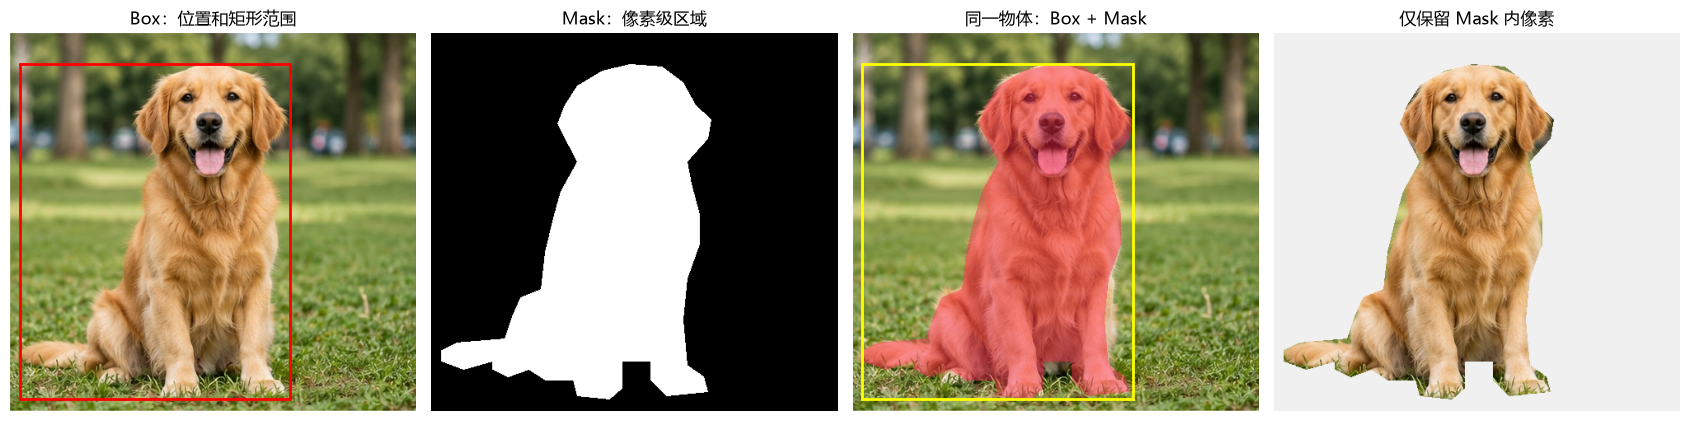

Box [x_min, y_min, x_max, y_max) = [12, 38, 340, 445)（右/下边界不包含）
Mask 面积：70846；Box 面积：133496
Box 中位于当前 Mask 外的像素占比：46.93%


In [5]:
from matplotlib.patches import Rectangle
x, y, bw, bh = cv2.boundingRect(mask)
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
axes[0].imshow(image_np)
axes[0].add_patch(Rectangle((x-.5, y-.5), bw, bh, fill=False, edgecolor='red', linewidth=2))
axes[0].set_title('Box：位置和矩形范围')
axes[1].imshow(mask, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Mask：像素级区域')
axes[2].imshow(overlay(image_np, mask))
axes[2].add_patch(Rectangle((x-.5, y-.5), bw, bh, fill=False, edgecolor='yellow', linewidth=2))
axes[2].set_title('同一物体：Box + Mask')
cutout = image_np.copy()
cutout[mask == 0] = 240
axes[3].imshow(cutout)
axes[3].set_title('仅保留 Mask 内像素')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)
mask_area = np.count_nonzero(mask)
box_area = bw * bh
print(f'Box [x_min, y_min, x_max, y_max) = [{x}, {y}, {x+bw}, {y+bh})（右/下边界不包含）')
print(f'Mask 面积：{mask_area}；Box 面积：{box_area}')
print(f'Box 中位于当前 Mask 外的像素占比：{1-mask_area/box_area:.2%}')
assert 0 < mask_area <= box_area

**回答：Box 表达“物体大致在哪里、有多大”，Mask 表达“哪些像素属于物体”。**

| 条件 | 保留的信息 | 本图表现 |
|---|---|---|
| Box | 位置、矩形宽高 | 尾巴拉宽外接框，框内包含较多草地，无法描述具体轮廓 |
| Mask | 像素区域和轮廓 | 更贴近身体和尾巴；手工多边形仍包含部分背景，未精细标注毛发和腿间空隙 |

Box 适合检测或粗略布局；Mask 适合分割和局部区域控制，但标注成本更高。框内覆盖率不代表分割质量。Canny 表达明暗边界，不提供物体归属。三类空间条件都需要与原图共享几何变换。